In [1]:
import pandas as pd

In [3]:
diamonds = pd.read_csv(r"G:\Data Analysis Journey\1. Diamond_Price\diamonds.csv")
print(diamonds.head())

   Unnamed: 0  carat      cut color clarity  depth  table  price     x     y  \
0           1   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98   
1           2   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84   
2           3   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07   
3           4   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23   
4           5   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35   

      z  
0  2.43  
1  2.31  
2  2.31  
3  2.63  
4  2.75  


In [4]:
diamonds.head(10)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,7,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,8,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,9,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,10,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [5]:
diamonds.shape

(53940, 11)

In [6]:
diamonds.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='object')

In [7]:
diamonds.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [8]:
diamonds.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

In [9]:
diamonds.duplicated().sum()

0

In [10]:
diamonds.dtypes

Unnamed: 0      int64
carat         float64
cut            object
color          object
clarity        object
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

In [11]:
diamonds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [12]:
(diamonds[["carat", "price", "x", "y", "z"]] <= 0).sum()

carat     0
price     0
x         8
y         7
z        20
dtype: int64

In [14]:
diamonds_clean = diamonds.copy()

In [15]:
(diamonds[["x","y","z"]]<0).sum()

x    0
y    0
z    0
dtype: int64

In [16]:
(diamonds[["x","y","z"]]==0).sum()

x     8
y     7
z    20
dtype: int64

In [20]:
invalid_rows = diamonds[
    (diamonds[["x","y","z"]]<=0).any(axis=1)
]

invalid_rows.shape[0]

20

In [21]:
diamonds_clean = diamonds[
    (diamonds[["x","y","z"]]>0).all(axis=1)
].copy()

In [22]:
diamonds_clean.shape

(53920, 11)

In [24]:
(diamonds_clean[["x","y","z"]] <= 0).sum()

x    0
y    0
z    0
dtype: int64

In [25]:
print("Original rows:", len(diamonds))
print("Cleaned rows:", len(diamonds_clean))
print("Rows removed:", len(diamonds) - len(diamonds_clean))

Original rows: 53940
Cleaned rows: 53920
Rows removed: 20


In [26]:
diamonds.duplicated().sum()

0

In [27]:
diamonds_clean.duplicated().sum()

0

In [28]:
diamonds_clean["price"].describe()

count    53920.000000
mean      3930.993231
std       3987.280446
min        326.000000
25%        949.000000
50%       2401.000000
75%       5323.250000
max      18823.000000
Name: price, dtype: float64

In [29]:
diamonds_clean["price"].mean()

3930.993230712166

In [30]:
diamonds_clean["price"].median()

2401.0

In [31]:
diamonds_clean["price"].min()

326

In [32]:
diamonds_clean["price"].max()

18823

In [33]:
diamonds_clean["price"].count()

53920

In [34]:
diamonds_clean[["carat","price"]].head(10)

,carat,price
0,0.23,326
1,0.21,326
2,0.23,327
3,0.29,334
4,0.31,335
5,0.24,336
6,0.24,336
7,0.26,337
8,0.22,337
9,0.23,338


In [35]:
diamonds_clean["carat"].corr(diamonds_clean["price"])

0.9215920634724073

In [36]:
import matplotlib.pyplot as plt

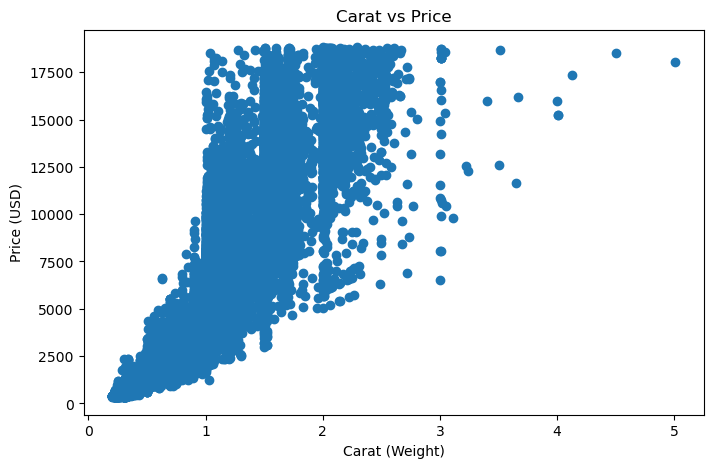

In [42]:
plt.figure(figsize=(8,5))

plt.scatter(
    diamonds_clean["carat"],
    diamonds_clean["price"]
)

plt.xlabel("Carat (Weight)")
plt.ylabel("Price (USD)")
plt.title("Carat vs Price")

plt.show()

In [43]:
diamonds_clean[diamonds_clean["carat"] >=5][
    ["carat","price","cut","color","clarity"]
]

,carat,price,cut,color,clarity
27415,5.01,18018,Fair,J,I1


In [45]:
diamonds_clean["carat"].max()

5.01

In [46]:
diamonds_clean["carat"].describe()

count    53920.000000
mean         0.797698
std          0.473795
min          0.200000
25%          0.400000
50%          0.700000
75%          1.040000
max          5.010000
Name: carat, dtype: float64

In [48]:
q1 = diamonds_clean["carat"].quantile(0.25)
q1

0.4

In [50]:
q3 = diamonds_clean["carat"].quantile(0.75)
q3

1.04

In [51]:
IQR = q3-q1
IQR

0.64

In [52]:
upper_limit = q3 + (1.5 * IQR)
upper_limit

2.0

In [54]:
carat_outliers = diamonds_clean[
    diamonds_clean["carat"] > upper_limit
]

carat_outliers.shape

(1883, 11)

In [55]:
carat_outliers["carat"].describe()

count    1883.000000
mean        2.153271
std         0.236568
min         2.010000
25%         2.020000
50%         2.060000
75%         2.200000
max         5.010000
Name: carat, dtype: float64

In [57]:
carat_outliers["carat"].count()

1883

In [58]:
diamonds_clean.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='object')

In [60]:
diamonds_clean["cut"].unique()

array(['Ideal', 'Premium', 'Good', 'Very Good', 'Fair'], dtype=object)

In [62]:
diamonds_clean["color"].unique()

array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object)

In [63]:
diamonds_clean["clarity"].unique()

array(['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF'],
      dtype=object)

In [65]:
diamonds_clean["cut"].value_counts()

Ideal        21548
Premium      13780
Very Good    12081
Good          4902
Fair          1609
Name: cut, dtype: int64

In [66]:
diamonds_clean["color"].value_counts()

G    11284
E     9797
F     9538
H     8298
D     6774
I     5421
J     2808
Name: color, dtype: int64

In [68]:
diamonds_clean["clarity"].value_counts()

SI1     13063
VS2     12254
SI2      9185
VS1      8170
VVS2     5066
VVS1     3654
IF       1790
I1        738
Name: clarity, dtype: int64

In [72]:
diamonds_clean.groupby("cut")["price"].mean() 

#Code	Meaning
#groupby("cut")	Groups diamonds according to their cut grade
#["price"]	Selects the price column
#.mean()	Calculates the average price for each cut category

cut
Fair         4357.500932
Good         3926.403509
Ideal        3456.941201
Premium      4579.684543
Very Good    3981.664101
Name: price, dtype: float64

In [73]:
diamonds_clean.groupby("cut")["price"].mean().sort_values(ascending=False)
#sort_values(ascending=False)

cut
Premium      4579.684543
Fair         4357.500932
Very Good    3981.664101
Good         3926.403509
Ideal        3456.941201
Name: price, dtype: float64

In [74]:
diamonds_clean.groupby("cut")["carat"].mean().sort_values(ascending=False)

cut
Fair         1.046078
Premium      0.891409
Good         0.848711
Very Good    0.806365
Ideal        0.702759
Name: carat, dtype: float64

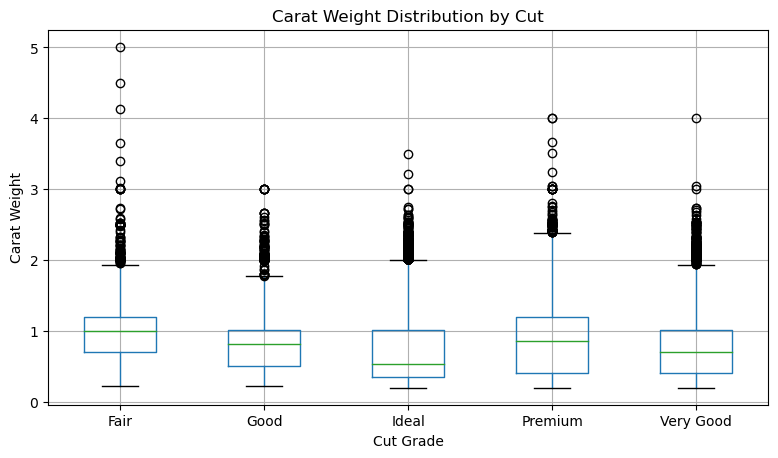

In [78]:
diamonds_clean.boxplot(
    column="carat",
    by="cut",
    figsize=(9,5)
)

plt.title("Carat Weight Distribution by Cut")
plt.suptitle("")
plt.xlabel ("Cut Grade")
plt.ylabel("Carat Weight")
plt.show()

In [79]:
diamonds_clean.groupby("color")["price"].mean().sort_values(ascending=False)

color
J    5323.818020
I    5089.973990
H    4480.942155
G    3996.876551
F    3725.080205
D    3168.106436
E    3076.752475
Name: price, dtype: float64

In [80]:
diamonds_clean.groupby("color")["carat"].mean().sort_values(ascending=False)

color
J    1.162137
I    1.026702
H    0.911174
G    0.770729
F    0.736480
E    0.657867
D    0.657715
Name: carat, dtype: float64

In [81]:
diamonds_clean.groupby("clarity")["price"].mean().sort_values(ascending=False)

clarity
SI2     5060.440174
SI1     3994.112608
I1      3926.189702
VS2     3922.866819
VS1     3839.144308
VVS2    3283.737071
IF      2864.839106
VVS1    2519.512315
Name: price, dtype: float64

In [83]:
diamonds_clean.groupby("clarity")["carat"].mean().sort_values(ascending=False)

clarity
I1      1.284146
SI2     1.077308
SI1     0.850272
VS2     0.763716
VS1     0.727108
VVS2    0.596202
IF      0.505123
VVS1    0.503131
Name: carat, dtype: float64

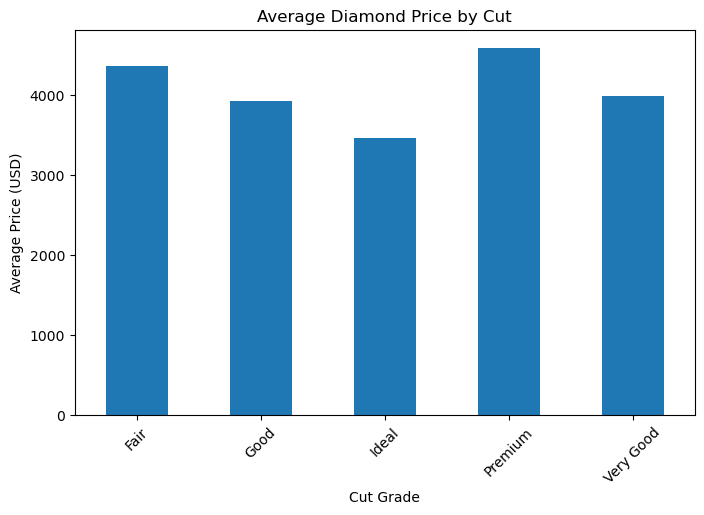

In [87]:
averages_price_cut = diamonds_clean.groupby("cut")["price"].mean()

averages_price_cut.plot(kind="bar", figsize=(8,5))

plt.title("Average Diamond Price by Cut")
plt.xlabel("Cut Grade")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.show()
#groupby("cut"): Groups diamonds by cut.
#.mean(): Calculates average price.
#.plot(kind="bar"): Creates a bar chart.
#plt.title(): Adds a chart title.

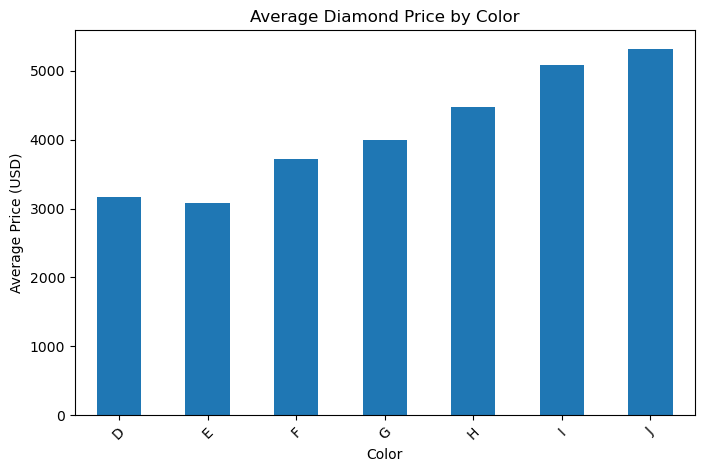

In [89]:
averages_price_color = diamonds_clean.groupby("color")["price"].mean()

averages_price_color.plot(kind="bar", figsize=(8,5))

plt.title("Average Diamond Price by Color")
plt.xlabel("Color")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.show()

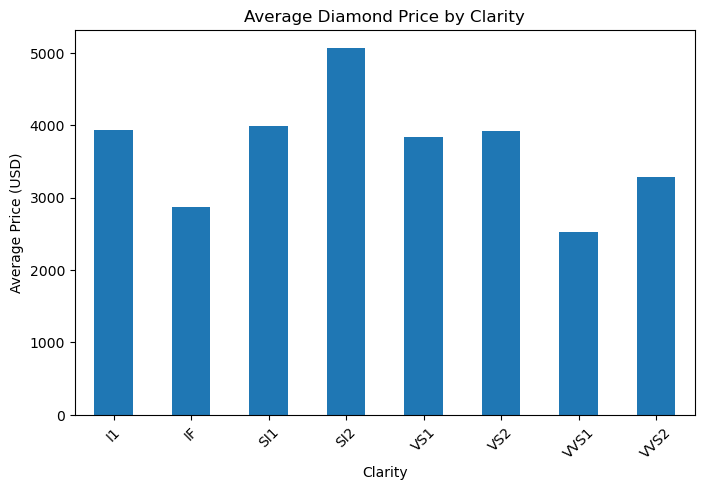

In [90]:
averages_price_clarity = diamonds_clean.groupby("clarity")["price"].mean()

averages_price_clarity.plot(kind="bar", figsize=(8,5))

plt.title("Average Diamond Price by Clarity")
plt.xlabel("Clarity")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.show()

In [95]:
original_rows = diamonds.shape[0]
cleaned_rows = diamonds_clean.shape[0]

removed_precentage = (
    (original_rows - cleaned_rows) / original_rows
) * 100

print("Original records:", original_rows)
print("Cleaned records:", cleaned_rows)
print("Removed percentage:", round(removed_precentage,2), "%")

Original records: 53940
Cleaned records: 53920
Removed percentage: 0.04 %
